# T3 - Modelos finales, edad, aditivos, estabilidad e incertidumbre
Marco VDS: predictibilidad (métricas en prueba reservada), estabilidad (semillas, bootstrap,
ruido) y computabilidad (todo reproducible con SEED = 42).

Orden del análisis:
1. Se reserva el 20 % de las MEZCLAS como prueba final (no se toca hasta el final).
2. Con el 80 % restante se ajustan hiperparámetros con GroupKFold por mezcla.
3. Se evalúa en la prueba reservada y se analiza el error por edad y por tipo de aditivo.
4. Se mide la estabilidad (bootstrap de mezclas y ruido en las entradas).
5. Se construyen intervalos de predicción (regresión por cuantiles) y se mide su cobertura.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

RAIZ = Path("..")
PROC = RAIZ / "data" / "processed"
FIGS = RAIZ / "docs" / "figuras_t3"
FIGS.mkdir(parents=True, exist_ok=True)
resultados = {}

df = pd.read_csv(PROC / "concreto_limpio.csv")
BASE = ["cemento", "escoria", "ceniza", "agua", "superplast", "grueso", "fino", "edad"]
EXT = BASE + ["a_c", "a_aglom", "prop_adiciones", "pasta_agregados", "log_edad"]


def con_derivadas(b):
    """Recalcula las variables derivadas desde las 8 originales (útil al añadir ruido)."""
    d = b[BASE].copy()
    aglom = d.cemento + d.escoria + d.ceniza
    d["a_c"] = d.agua / d.cemento
    d["a_aglom"] = d.agua / aglom
    d["prop_adiciones"] = (d.escoria + d.ceniza) / aglom
    d["pasta_agregados"] = (aglom + d.agua) / (d.grueso + d.fino)
    d["log_edad"] = np.log(d.edad)
    return d[EXT]


def metricas(y, p):
    return {"R2": round(float(r2_score(y, p)), 3),
            "RMSE": round(float(np.sqrt(mean_squared_error(y, p))), 2),
            "MAE": round(float(mean_absolute_error(y, p)), 2)}

## 1. Prueba reservada por mezclas
Se reserva el 20 % de las mezclas. Ninguna mezcla aparece a la vez en desarrollo y prueba.

In [2]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
i_dev, i_test = next(gss.split(df, groups=df["grupo"]))
dev, test = df.iloc[i_dev].reset_index(drop=True), df.iloc[i_test].reset_index(drop=True)
Xd, yd, gd = dev[EXT], dev["fc"].values, dev["grupo"].values
Xt, yt = test[EXT], test["fc"].values
assert set(dev.grupo).isdisjoint(set(test.grupo))
print(f"Desarrollo: {len(dev)} filas / {dev.grupo.nunique()} mezclas | "
      f"Prueba: {len(test)} filas / {test.grupo.nunique()} mezclas")
resultados["split"] = {"dev_filas": len(dev), "dev_mezclas": int(dev.grupo.nunique()),
                       "test_filas": len(test), "test_mezclas": int(test.grupo.nunique())}

Desarrollo: 810 filas / 342 mezclas | Prueba: 195 filas / 86 mezclas


## 2. Ajuste de hiperparámetros (búsqueda aleatoria + GroupKFold de 5 pliegues)

In [3]:
cv = GroupKFold(n_splits=5)
espacios = {
    "Random Forest": (RandomForestRegressor(random_state=SEED, n_jobs=-1), {
        "n_estimators": randint(150, 500), "max_depth": [None, 10, 15, 20],
        "min_samples_leaf": randint(1, 6), "max_features": uniform(0.4, 0.6)}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=SEED), {
        "n_estimators": randint(200, 700), "learning_rate": loguniform(0.02, 0.2),
        "max_depth": randint(2, 6), "subsample": uniform(0.6, 0.4),
        "min_samples_leaf": randint(1, 8)}),
    "MLP": (make_pipeline(StandardScaler(), MLPRegressor(max_iter=3000, random_state=SEED)), {
        "mlpregressor__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64), (64, 64, 32)],
        "mlpregressor__alpha": loguniform(1e-5, 1e-1),
        "mlpregressor__learning_rate_init": loguniform(5e-4, 1e-2)}),
}
mejores, tabla = {}, {}
lin = LinearRegression().fit(Xd, yd)
oof_cv = lambda m: np.mean([r2_score(yd[v], m.fit(Xd.iloc[t], yd[t]).predict(Xd.iloc[v]))
                            for t, v in cv.split(Xd, yd, gd)])
tabla["Regresión lineal"] = {"R2_cv": round(float(oof_cv(LinearRegression())), 3),
                             **{f"{k}_test": v for k, v in metricas(yt, lin.predict(Xt)).items()}}
mejores["Regresión lineal"] = lin
for nombre, (est, esp) in espacios.items():
    bus = RandomizedSearchCV(est, esp, n_iter=12, cv=cv, scoring="r2", n_jobs=-1,
                             random_state=SEED, refit=True)
    bus.fit(Xd, yd, groups=gd)
    mejores[nombre] = bus.best_estimator_
    tabla[nombre] = {"R2_cv": round(float(bus.best_score_), 3),
                     **{f"{k}_test": v for k, v in metricas(yt, bus.predict(Xt)).items()},
                     "mejores_parametros": {k: (round(v, 5) if isinstance(v, float) else v)
                                            for k, v in bus.best_params_.items()}}
    print(nombre, tabla[nombre])
tab = pd.DataFrame(tabla).T[["R2_cv", "R2_test", "RMSE_test", "MAE_test"]]
print(tab)
resultados["modelos_finales"] = tabla
MEJOR = tab["R2_test"].astype(float).idxmax()
print("Mejor en prueba reservada:", MEJOR)

Random Forest {'R2_cv': 0.871, 'R2_test': 0.905, 'RMSE_test': 4.99, 'MAE_test': 3.6, 'mejores_parametros': {'max_depth': 10, 'max_features': np.float64(0.40424), 'min_samples_leaf': 1, 'n_estimators': 198}}
Gradient Boosting {'R2_cv': 0.881, 'R2_test': 0.922, 'RMSE_test': 4.5, 'MAE_test': 3.26, 'mejores_parametros': {'learning_rate': np.float64(0.03167), 'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 519, 'subsample': np.float64(0.78671)}}
MLP {'R2_cv': 0.86, 'R2_test': 0.892, 'RMSE_test': 5.31, 'MAE_test': 4.1, 'mejores_parametros': {'mlpregressor__alpha': np.float64(0.08569), 'mlpregressor__hidden_layer_sizes': (32,), 'mlpregressor__learning_rate_init': np.float64(0.00057)}}
                   R2_cv R2_test RMSE_test MAE_test
Regresión lineal   0.797   0.839      6.48     5.29
Random Forest      0.871   0.905      4.99      3.6
Gradient Boosting  0.881   0.922       4.5     3.26
MLP                 0.86   0.892      5.31      4.1
Mejor en prueba reservada: Gradient Boosting


## 3. Predicho vs. real en la prueba reservada

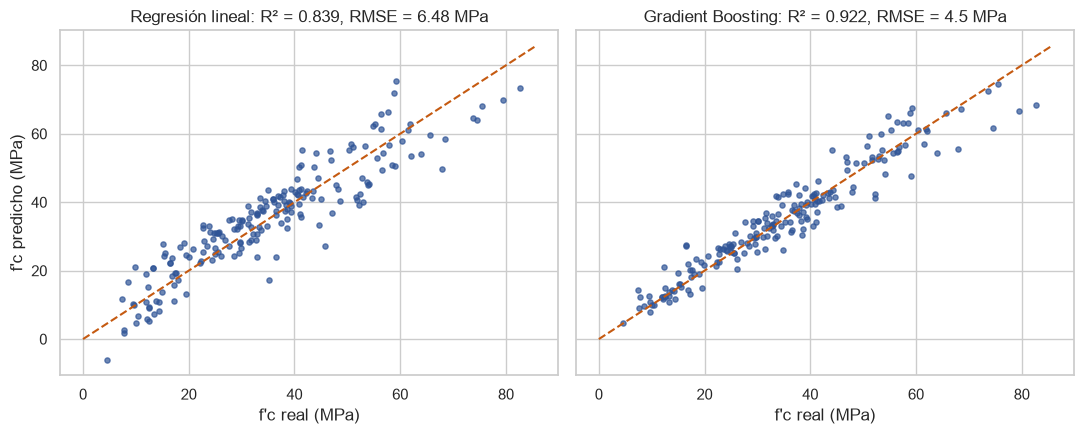

In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, nom in zip(axes, ["Regresión lineal", MEJOR]):
    p = mejores[nom].predict(Xt)
    ax.scatter(yt, p, s=14, alpha=0.7, color="#2F5496")
    lim = [0, max(yt.max(), p.max()) + 3]
    ax.plot(lim, lim, "--", color="#C55A11")
    m = metricas(yt, p)
    ax.set_title(f"{nom}: R² = {m['R2']}, RMSE = {m['RMSE']} MPa")
    ax.set_xlabel("f'c real (MPa)")
axes[0].set_ylabel("f'c predicho (MPa)")
fig.tight_layout()
fig.savefig(FIGS / "fig7_predicho_vs_real.png", dpi=150)
plt.show()

## 4. Pregunta del profesor sobre la edad: error por rango de edad
Se usan predicciones fuera de muestra (GroupKFold) sobre el conjunto de desarrollo, con
los hiperparámetros ya elegidos, para tener más ensayos por rango. Se reporta el error
ABSOLUTO (MPa) y el RELATIVO (% del valor real).

Distribución de edades (desarrollo):
edad
1        2
3      105
7      105
14      49
28     334
56      64
90      48
91      13
100     39
120      2
180     22
270     11
360      6
365     10
           modelo    rango   n  RMSE  MAE  error_rel_%
 Regresión lineal    1-7 d 212  6.33 4.86         32.2
 Regresión lineal  14-28 d 383  7.41 5.53         17.8
 Regresión lineal 56-100 d 164  7.41 6.00         12.6
 Regresión lineal   >100 d  51  9.59 8.43         19.3
Gradient Boosting    1-7 d 212  4.88 3.44         20.1
Gradient Boosting  14-28 d 383  5.93 3.92         11.2
Gradient Boosting 56-100 d 164  6.29 4.71         10.0
Gradient Boosting   >100 d  51  4.14 3.22          7.2


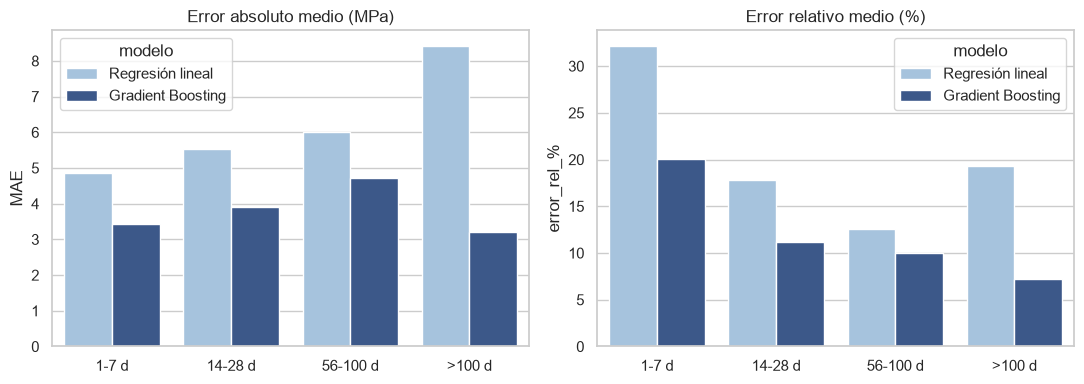

In [5]:
def predicciones_oof(modelo):
    p = np.zeros(len(Xd))
    for t, v in cv.split(Xd, yd, gd):
        m = type(modelo)(**modelo.get_params()) if not hasattr(modelo, "steps") else None
        if m is None:
            from sklearn.base import clone
            m = clone(modelo)
        p[v] = m.fit(Xd.iloc[t], yd[t]).predict(Xd.iloc[v])
    return p


oof = {n: predicciones_oof(m) for n, m in mejores.items()}
print("Distribución de edades (desarrollo):")
print(dev.edad.value_counts().sort_index().to_string())

bins = pd.cut(dev.edad, [0, 7, 28, 100, 400], labels=["1-7 d", "14-28 d", "56-100 d", ">100 d"])
filas_edad = []
for nom, p in oof.items():
    for rango in bins.cat.categories:
        s = (bins == rango).values
        err = p[s] - yd[s]
        filas_edad.append({"modelo": nom, "rango": rango, "n": int(s.sum()),
                           "RMSE": round(float(np.sqrt(np.mean(err ** 2))), 2),
                           "MAE": round(float(np.mean(np.abs(err))), 2),
                           "error_rel_%": round(float(np.mean(np.abs(err) / yd[s]) * 100), 1)})
edad_df = pd.DataFrame(filas_edad)
print(edad_df[edad_df.modelo.isin(["Regresión lineal", MEJOR])].to_string(index=False))
resultados["error_por_edad"] = filas_edad

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sub = edad_df[edad_df.modelo.isin(["Regresión lineal", MEJOR])]
sns.barplot(data=sub, x="rango", y="MAE", hue="modelo", ax=axes[0], palette=["#9DC3E6", "#2F5496"])
axes[0].set_title("Error absoluto medio (MPa)")
sns.barplot(data=sub, x="rango", y="error_rel_%", hue="modelo", ax=axes[1],
            palette=["#9DC3E6", "#2F5496"])
axes[1].set_title("Error relativo medio (%)")
for a in axes:
    a.set_xlabel("")
fig.tight_layout()
fig.savefig(FIGS / "fig8_error_por_edad.png", dpi=150)
plt.show()

## 5. Pregunta del profesor sobre los aditivos
¿Qué algoritmo capturó mejor la relación no lineal de escoria, ceniza y superplastificante?
Se compara el R² fuera de muestra en subconjuntos de mezclas según qué aditivos contienen.

In [6]:
sub_adit = {
    "Sin aditivos": ((dev.escoria == 0) & (dev.ceniza == 0) & (dev.superplast == 0)).values,
    "Con escoria o ceniza": ((dev.escoria > 0) | (dev.ceniza > 0)).values,
    "Con superplastificante": (dev.superplast > 0).values,
    "Con escoria/ceniza y superplast.": (((dev.escoria > 0) | (dev.ceniza > 0))
                                         & (dev.superplast > 0)).values,
}
filas_ad = []
for nom, p in oof.items():
    for sname, s in sub_adit.items():
        filas_ad.append({"modelo": nom, "subconjunto": sname, "n": int(s.sum()),
                         "R2": round(float(r2_score(yd[s], p[s])), 3),
                         "RMSE": round(float(np.sqrt(mean_squared_error(yd[s], p[s]))), 2)})
ad_df = pd.DataFrame(filas_ad)
print(ad_df.pivot(index="subconjunto", columns="modelo", values="R2"))
print(ad_df.pivot(index="subconjunto", columns="modelo", values="RMSE"))
resultados["aditivos"] = filas_ad

modelo                            Gradient Boosting    MLP  Random Forest  \
subconjunto                                                                 
Con escoria o ceniza                          0.876  0.843          0.861   
Con escoria/ceniza y superplast.              0.858  0.824          0.840   
Con superplastificante                        0.849  0.820          0.833   
Sin aditivos                                  0.906  0.914          0.910   

modelo                            Regresión lineal  
subconjunto                                         
Con escoria o ceniza                         0.790  
Con escoria/ceniza y superplast.             0.791  
Con superplastificante                       0.782  
Sin aditivos                                 0.831  
modelo                            Gradient Boosting   MLP  Random Forest  \
subconjunto                                                                
Con escoria o ceniza                           5.73  6.44          

## 6. Estabilidad (VDS)
a) Bootstrap de MEZCLAS: se remuestrean mezclas completas, se reentrena y se evalúa en la prueba.
b) Ruido en las entradas: se perturban las 8 variables originales (2 % de su desv. estándar
   multiplicado por un factor) y se recalculan las derivadas; se mide cuánto cae el R².

In [7]:
from sklearn.base import clone

rng = np.random.default_rng(SEED)
mezclas = np.unique(gd)
boot = {n: [] for n in ["Random Forest", "Gradient Boosting", "MLP"]}
for b in range(20):
    elegidas = rng.choice(mezclas, size=len(mezclas), replace=True)
    idx = np.concatenate([np.where(gd == g)[0] for g in elegidas])
    for n in boot:
        m = clone(mejores[n]).fit(Xd.iloc[idx], yd[idx])
        boot[n].append(r2_score(yt, m.predict(Xt)))
est_boot = {n: {"media": round(float(np.mean(v)), 3), "de": round(float(np.std(v)), 3),
                "min": round(float(np.min(v)), 3), "max": round(float(np.max(v)), 3)}
            for n, v in boot.items()}
print("Bootstrap de mezclas (R² en prueba, 20 réplicas):")
print(pd.DataFrame(est_boot).T)
resultados["bootstrap_mezclas"] = est_boot

ruido = {}
sd = test[BASE].std()
for nivel in [0.0, 0.02, 0.05, 0.10]:
    r = {}
    for n in ["Regresión lineal", "Random Forest", "Gradient Boosting", "MLP"]:
        vals = []
        for rep in range(10):
            rr = np.random.default_rng(rep)
            ruidoso = test[BASE] + rr.normal(0, 1, test[BASE].shape) * sd.values * nivel
            ruidoso[["cemento", "escoria", "ceniza", "agua", "superplast", "grueso", "fino"]] = \
                ruidoso[["cemento", "escoria", "ceniza", "agua", "superplast", "grueso",
                         "fino"]].clip(lower=0)
            ruidoso["edad"] = ruidoso["edad"].clip(lower=1)
            ruidoso["cemento"] = ruidoso["cemento"].clip(lower=1)
            vals.append(r2_score(yt, mejores[n].predict(con_derivadas(ruidoso))))
        r[n] = round(float(np.mean(vals)), 3)
    ruido[f"{int(nivel * 100)} %"] = r
ruido_df = pd.DataFrame(ruido).T
print("R² en prueba al añadir ruido (fracción de la desv. estándar de cada variable):")
print(ruido_df)
resultados["ruido_entradas"] = ruido

Bootstrap de mezclas (R² en prueba, 20 réplicas):
                   media     de    min    max
Random Forest      0.881  0.011  0.861  0.903
Gradient Boosting  0.892  0.013  0.861  0.914
MLP                0.882  0.016  0.847  0.909
R² en prueba al añadir ruido (fracción de la desv. estándar de cada variable):
      Regresión lineal  Random Forest  Gradient Boosting    MLP
0 %              0.839          0.905              0.922  0.892
2 %              0.824          0.897              0.914  0.884
5 %              0.785          0.875              0.893  0.857
10 %             0.727          0.837              0.855  0.803


## 7. Predicción probabilística: intervalos de predicción del 90 %
Gradient Boosting con pérdida de cuantiles (5 % y 95 %), con los hiperparámetros ya elegidos.
Métricas: COBERTURA (¿qué fracción de los valores reales cae dentro del intervalo? lo ideal
es ~90 %) y ANCHO medio del intervalo.

Cobertura del intervalo 90 %: 78.5% | ancho medio: 14.2 MPa


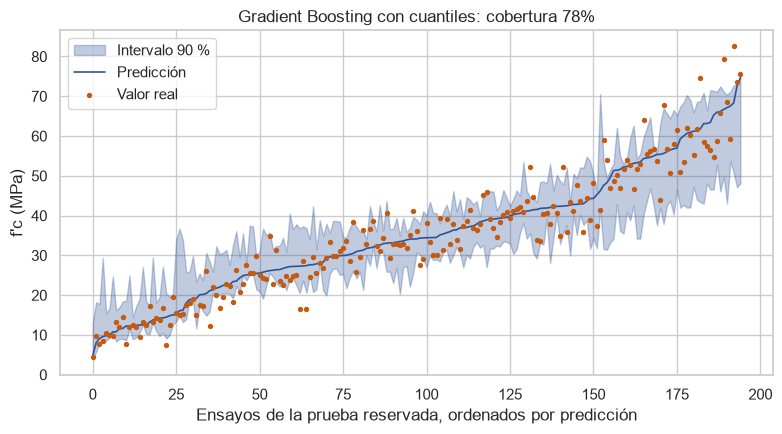

In [8]:
pg = {k: v for k, v in mejores["Gradient Boosting"].get_params().items()
      if k in ("n_estimators", "learning_rate", "max_depth", "subsample", "min_samples_leaf")}
bajo = GradientBoostingRegressor(loss="quantile", alpha=0.05, random_state=SEED, **pg).fit(Xd, yd)
alto = GradientBoostingRegressor(loss="quantile", alpha=0.95, random_state=SEED, **pg).fit(Xd, yd)
centro = mejores["Gradient Boosting"].predict(Xt)
lo, hi = bajo.predict(Xt), alto.predict(Xt)
lo, hi = np.minimum(lo, centro), np.maximum(hi, centro)
cobertura = float(np.mean((yt >= lo) & (yt <= hi)))
ancho = float(np.mean(hi - lo))
print(f"Cobertura del intervalo 90 %: {cobertura:.1%} | ancho medio: {ancho:.1f} MPa")
resultados["intervalos_90"] = {"cobertura": round(cobertura, 3), "ancho_medio_MPa": round(ancho, 1)}

o = np.argsort(centro)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(range(len(o)), lo[o], hi[o], alpha=0.3, color="#2F5496", label="Intervalo 90 %")
ax.plot(range(len(o)), centro[o], color="#2F5496", lw=1.2, label="Predicción")
ax.scatter(range(len(o)), yt[o], s=8, color="#C55A11", label="Valor real", zorder=3)
ax.set_xlabel("Ensayos de la prueba reservada, ordenados por predicción")
ax.set_ylabel("f'c (MPa)")
ax.set_title(f"Gradient Boosting con cuantiles: cobertura {cobertura:.0%}")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "fig9_intervalos.png", dpi=150)
plt.show()

### 7b. Calibración conformal (corrige la cobertura)
Los cuantiles directos quedaron demasiado estrechos. La predicción conformal usa los
errores fuera de muestra (GroupKFold) del conjunto de desarrollo: se toma el cuantil 90 %
del error absoluto y se suma y resta a la predicción. Garantiza una cobertura cercana al
90 % sin suponer ninguna distribución, a cambio de un ancho constante.
Variante adaptativa: el error se normaliza por la predicción, para que el intervalo sea
proporcionalmente más ancho donde la resistencia es mayor.

Conformal constante:  cobertura 92.8% | ancho 16.8 MPa
Conformal relativo:   cobertura 95.4% | ancho medio 19.0 MPa
             n  constante  relativo
1-7 d     41.0      0.951     0.854
14-28 d   98.0      0.908     0.969
56-100 d  45.0      0.933     1.000
>100 d    11.0      1.000     1.000


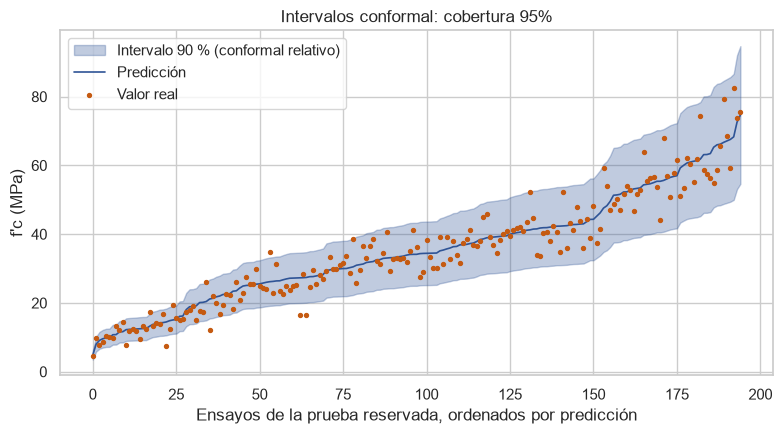

Guardado: ..\data\processed\resultados_t3_modelos.json


In [9]:
res_abs = np.abs(oof["Gradient Boosting"] - yd)
q_abs = float(np.quantile(res_abs, 0.90))
lo_c, hi_c = centro - q_abs, centro + q_abs
cob_c = float(np.mean((yt >= lo_c) & (yt <= hi_c)))

res_rel = res_abs / np.maximum(oof["Gradient Boosting"], 1)
q_rel = float(np.quantile(res_rel, 0.90))
lo_r, hi_r = centro - q_rel * centro, centro + q_rel * centro
cob_r = float(np.mean((yt >= lo_r) & (yt <= hi_r)))

print(f"Conformal constante:  cobertura {cob_c:.1%} | ancho {2 * q_abs:.1f} MPa")
print(f"Conformal relativo:   cobertura {cob_r:.1%} | ancho medio {np.mean(hi_r - lo_r):.1f} MPa")

# cobertura por rango de edad (¿el intervalo es confiable a edades tempranas?)
rangos_t = pd.cut(test.edad, [0, 7, 28, 100, 400], labels=["1-7 d", "14-28 d", "56-100 d", ">100 d"])
cob_edad = {}
for rg in rangos_t.cat.categories:
    s = (rangos_t == rg).values
    cob_edad[rg] = {"n": int(s.sum()),
                    "constante": round(float(np.mean((yt[s] >= lo_c[s]) & (yt[s] <= hi_c[s]))), 3),
                    "relativo": round(float(np.mean((yt[s] >= lo_r[s]) & (yt[s] <= hi_r[s]))), 3)}
print(pd.DataFrame(cob_edad).T)
resultados["intervalos_conformal"] = {
    "constante": {"cobertura": round(cob_c, 3), "ancho_MPa": round(2 * q_abs, 1)},
    "relativo": {"cobertura": round(cob_r, 3), "ancho_medio_MPa": round(float(np.mean(hi_r - lo_r)), 1)},
    "cobertura_por_edad": cob_edad}

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(range(len(o)), lo_r[o], hi_r[o], alpha=0.3, color="#2F5496", label="Intervalo 90 % (conformal relativo)")
ax.plot(range(len(o)), centro[o], color="#2F5496", lw=1.2, label="Predicción")
ax.scatter(range(len(o)), yt[o], s=8, color="#C55A11", label="Valor real", zorder=3)
ax.set_xlabel("Ensayos de la prueba reservada, ordenados por predicción")
ax.set_ylabel("f'c (MPa)")
ax.set_title(f"Intervalos conformal: cobertura {cob_r:.0%}")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "fig10_intervalos_conformal.png", dpi=150)
plt.show()

with open(PROC / "resultados_t3_modelos.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=str)
print("Guardado:", PROC / "resultados_t3_modelos.json")